In [8]:
from dotenv import load_dotenv
load_dotenv()  # take environment variables from .env.

True

### 1.没有记忆

In [12]:
from langchain.agents import create_agent
agent = create_agent(
    model="deepseek-chat",
    system_prompt="你是一个智能助手，你使用工具来解决用户问题。"
)

In [17]:
from langchain.messages import HumanMessage
# 调用工具
response = agent.invoke(
    {"messages": [HumanMessage(content="你好，我叫李华，我最喜欢小猫")]}
)
print(response["messages"][-1].content_blocks)

[{'type': 'text', 'text': '你好，李华！很高兴认识你，喜欢小猫真棒，小猫很可爱呢。有什么我可以帮你的吗？'}]


In [18]:
response = agent.invoke(
    {"messages": [HumanMessage(content="我最喜欢什么动物")]}
)
print(response["messages"][-1].content_blocks)

[{'type': 'text', 'text': '你还没有告诉我你喜欢什么动物呀 😊 我无法从对话中知道你的偏好。不过你可以告诉我，我可以帮你分析或聊聊这种动物的特点！你最喜欢什么动物呢？'}]



### 2.记忆的分类

对于智能体而言，记忆分为了两类：
- 短期记忆（short-term memory）:当前任务或会话的上下文（Working Memory 或 Session Memory）
- 长期记忆（long-term memory):跨任务或会话的经验与知识（Persistent Memory）
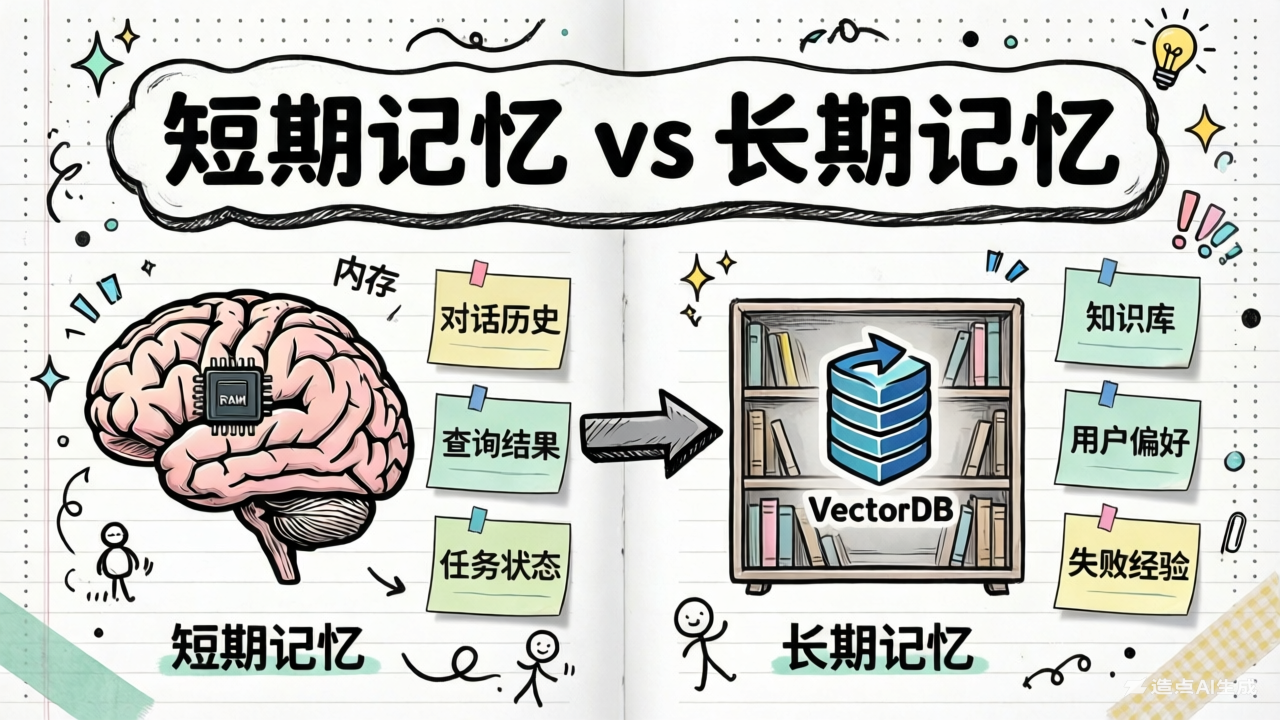
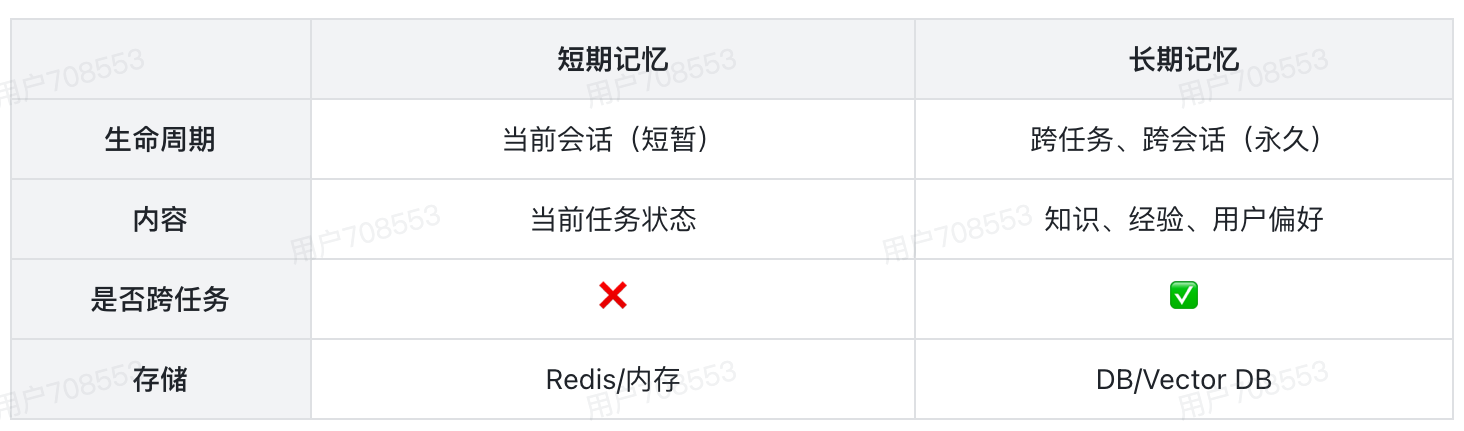

### 3.短期记忆
短期记忆通常生命周期是当前会话，所以我们也可以称为会话记忆。Agent的会话记忆通常包含三部分：
- 对话历史
- 查询结果
- 任务状态

对于简单的Agent来说，任务没有做拆分，也就不需要记录任务状态，只用考虑会话历史和查询结果就可以了
LangChain提供了自动化的记忆管理方案：
- 首先，LangChain把会话记忆（也就是Messages列表）记录为AgentState的一部分
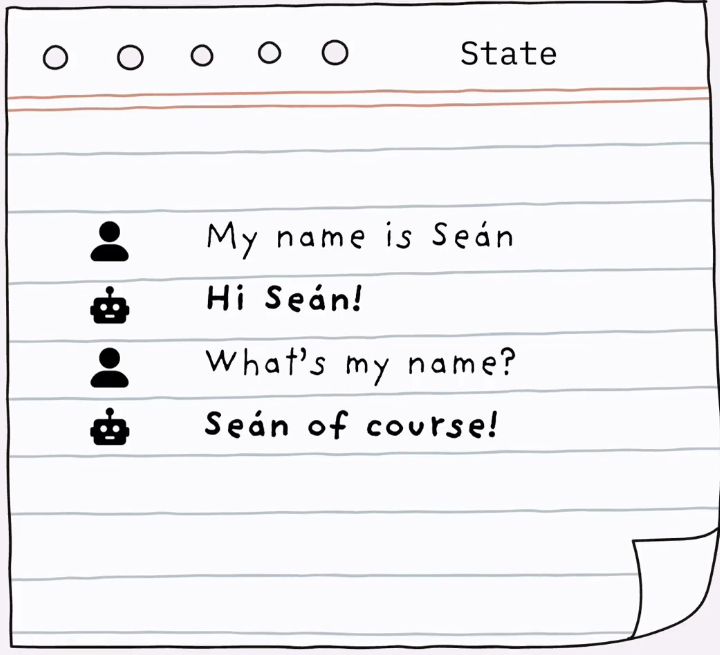
- AgentState通过Checkpointer对象来保存，每一次与AI的交互都会生成一个快照，记录为一个StateSnapshot，把同一会话的所有StateSnapshot组合在一起，就是完整的会话历史了。
- 为了区分不同的会话记忆，不同会话需要设定各自的thread_id，相同会话则使用相同thread_id
- 向Agent发起会话时必须指定自己的thread_id以唤起对应的会话记忆
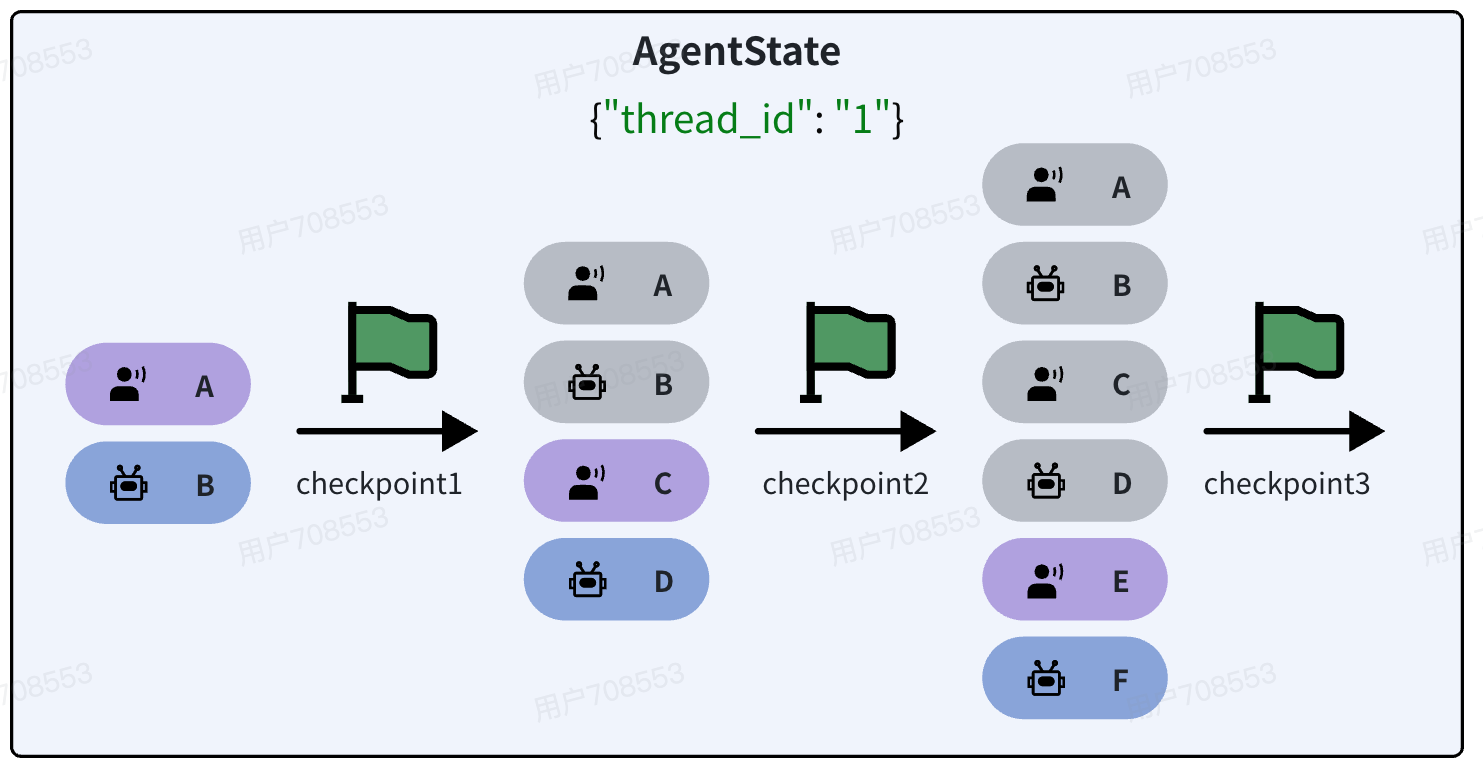

In [21]:
from langchain.agents import create_agent
from langgraph.checkpoint.memory import InMemorySaver

agent = create_agent(
    model="deepseek-chat",
    system_prompt="你是一个智能助手，你使用工具来解决用户问题。",
    checkpointer=InMemorySaver(),
)
config = {"configurable": {"thread_id": "1"}}
response = agent.invoke(
    {"messages": [HumanMessage(content="你好，我叫李华，我最喜欢小猫")]},
    config
)
print(response)

{'messages': [HumanMessage(content='你好，我叫李华，我最喜欢小猫', additional_kwargs={}, response_metadata={}, id='5a0578a2-b2f6-41c0-8f58-efab95558336'), AIMessage(content='你好，李华！很高兴认识你～喜欢小猫的人一定很有爱心。你养猫了吗？还是喜欢去猫咖或者看猫咪视频呢？🐱', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 34, 'prompt_tokens': 26, 'total_tokens': 60, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 26}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6', 'id': '93115ac1-2c44-4706-a6fd-86141a498ea8', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1c36e-1d17-76f6-b85d-744559a1fd5a-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 26, 'output_tokens': 34, 'total_tokens': 60, 'input_token_details': {'cache_rea

In [22]:
response = agent.invoke(
    {"messages": [HumanMessage(content="我最喜欢什么动物")]},
    config
)
print(response)

{'messages': [HumanMessage(content='你好，我叫李华，我最喜欢小猫', additional_kwargs={}, response_metadata={}, id='5a0578a2-b2f6-41c0-8f58-efab95558336'), AIMessage(content='你好，李华！很高兴认识你～喜欢小猫的人一定很有爱心。你养猫了吗？还是喜欢去猫咖或者看猫咪视频呢？🐱', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 34, 'prompt_tokens': 26, 'total_tokens': 60, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 26}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6', 'id': '93115ac1-2c44-4706-a6fd-86141a498ea8', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1c36e-1d17-76f6-b85d-744559a1fd5a-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 26, 'output_tokens': 34, 'total_tokens': 60, 'input_token_details': {'cache_rea

### 4. 持久化Memory
LangChain也提供了很多持久化存储的checkpointer，例如：
- SqlLiteSaver ：基于sqlite存储
- PostgresSaver ：基于Postgres存储
- CosmosDBSaver ：使用Azure Cosmos DB的实现

我们以SqlLiteSaver 为例来讲解如何自定义Memory存储方案。

In [39]:
import sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver
from langchain.agents import create_agent

# 初始化checkpointer
checkpointer = SqliteSaver(sqlite3.connect("resources/checkpoint.db", check_same_thread=False))
# 自动建表
checkpointer.setup()

# 创建agent
agent = create_agent(
    "deepseek-chat",
    checkpointer=checkpointer,
)

In [40]:
from langchain.messages import HumanMessage

config = {"configurable": {"thread_id": "thread_2"}}
response = agent.invoke(
    {"messages": [HumanMessage(content="你好，我叫李华，我最喜欢小猫")]},
    config
)
print(response)

{'messages': [HumanMessage(content='你好，我叫李华，我最喜欢小猫', additional_kwargs={}, response_metadata={}, id='c2120a96-d7ac-462f-940b-7058ce927c8a'), AIMessage(content='你好，李华！很高兴认识你。小猫确实非常可爱，它们软软的毛、圆圆的眼睛，还有那种俏皮又温柔的性格，真的很让人喜欢。你养小猫了吗？还是只是特别喜欢它们？', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 44, 'prompt_tokens': 13, 'total_tokens': 57, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 13}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6', 'id': '81df783c-90d0-4c8f-88b9-000ebc3bbd64', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1c37b-e228-7755-be36-5882116f1d28-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 13, 'output_tokens': 44, 'total_tokens': 57, 'input_to

In [41]:
response = agent.invoke(
    {"messages": [HumanMessage(content="我最喜欢什么动物")]},
    config
)
print(response)

{'messages': [HumanMessage(content='你好，我叫李华，我最喜欢小猫', additional_kwargs={}, response_metadata={}, id='c2120a96-d7ac-462f-940b-7058ce927c8a'), AIMessage(content='你好，李华！很高兴认识你。小猫确实非常可爱，它们软软的毛、圆圆的眼睛，还有那种俏皮又温柔的性格，真的很让人喜欢。你养小猫了吗？还是只是特别喜欢它们？', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 44, 'prompt_tokens': 13, 'total_tokens': 57, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 13}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6', 'id': '81df783c-90d0-4c8f-88b9-000ebc3bbd64', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1c37b-e228-7755-be36-5882116f1d28-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 13, 'output_tokens': 44, 'total_tokens': 57, 'input_to

### 5.记忆管理策略
由于会话记忆要保存会话的历史，并且在调用LLM时携带历史消息列表。而当会话越来越长时，历史消息就可能超过LLM的上下文限制。例如，DeepSeek的上下文不能超过1M.

一旦会话历史超过上下文窗口，就会出现上下文丢失的情况，从而导致丢失记忆。而且即便不丢失，太长的上下文容易让模型出现“注意力分散”问题，模型的响应速度、回答质量会大大降低。

解决这一问题，通常有以下几种手段：
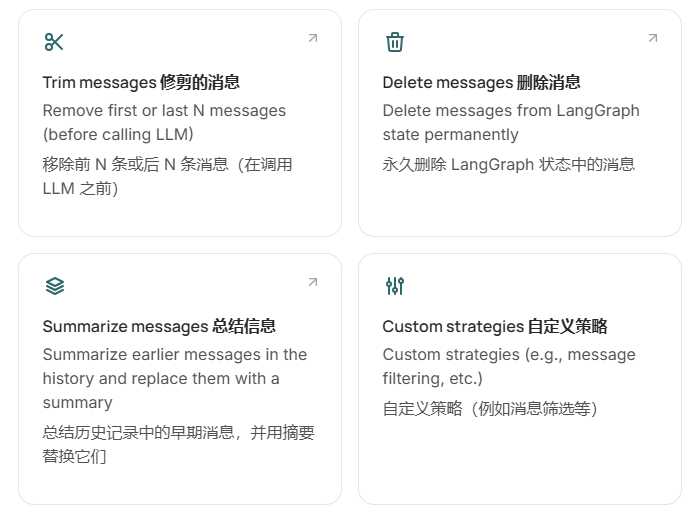

修剪消息并不是真正的删除消息，在AgentState中的消息列表依然是完整的，只不过发送给LLM之前会进行修剪，只保留一部分消息。修剪消息并不是真正的删除消息，在AgentState中的消息列表依然是完整的，只不过发送给LLM之前会进行修剪，只保留一部分消息。
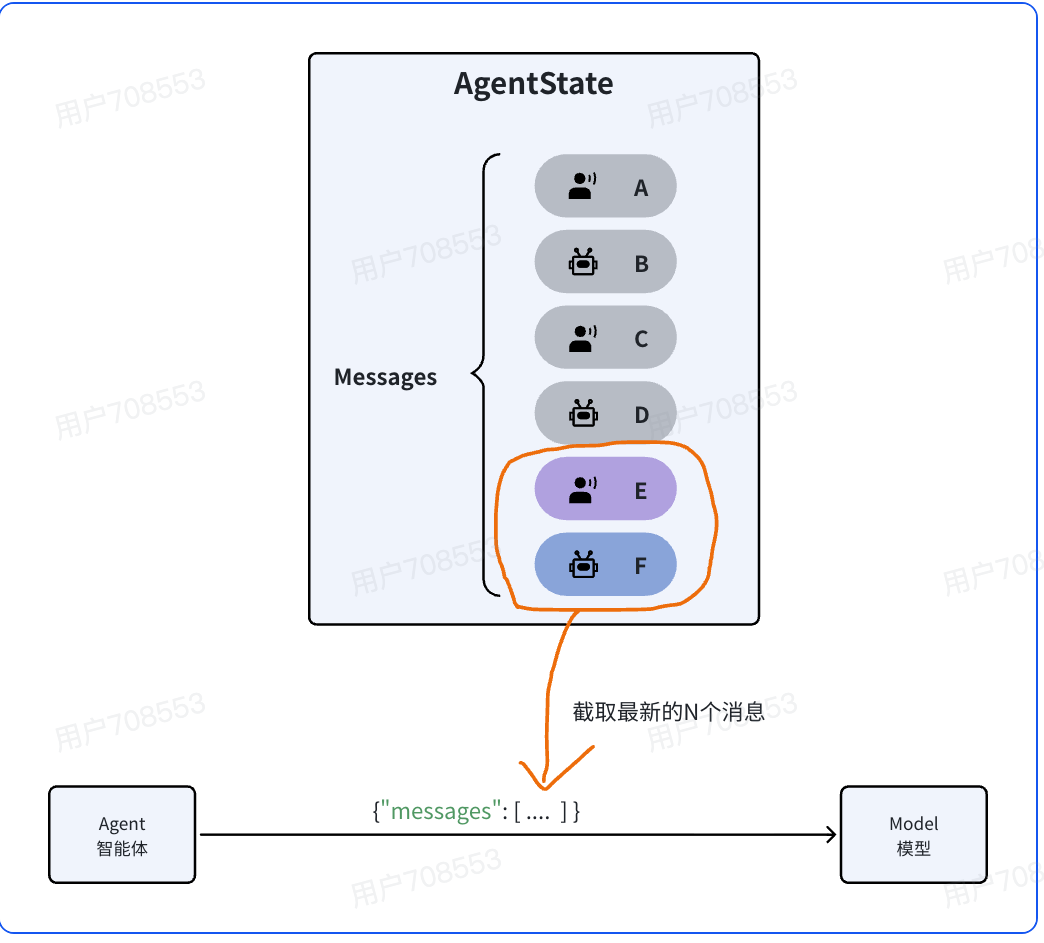

删除消息与修剪不同：
- 修剪消息：只是从State中选取一部分消息发送给模型
- 删除消息：直接删除State中保存的消息，也就是说消息历史中不再存在！

不管是修剪还是删除，都会导致一部分消息丢失，从而丢失记忆。所以就有了第三种策略：总结消息（Summarize Messages）
它的思路很简单，就是把历史的消息利用大模型总结出摘要，然后把最新的消息拼接在一起作为新的消息列表发送给大模型，这样既不会超出模型的上下文窗口限制，还能尽量保留所有的记忆。
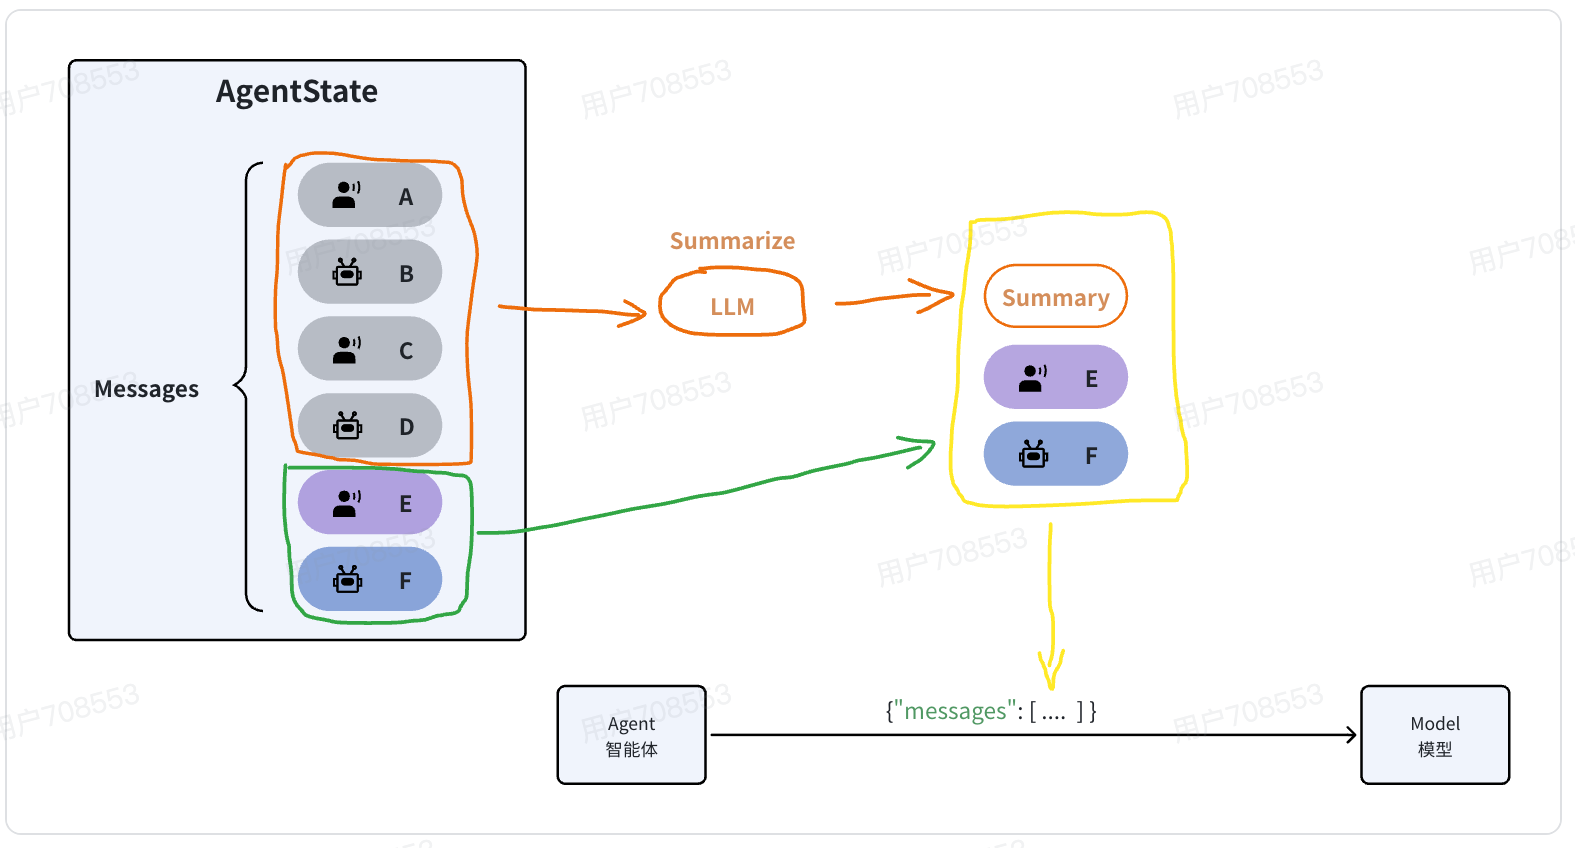

In [44]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.runnables import RunnableConfig

# 初始化checkpointer
checkpointer = InMemorySaver()

# 初始化中间件
middleware = SummarizationMiddleware(
    model="deepseek-chat",
    trigger=("messages", 3), #  触发时机，当消息数超过3时，进行总结
    keep=("messages", 1) #  保留的会话数，超过2条
)

# 创建agent
agent = create_agent(
    model="deepseek-chat",
    middleware=[middleware],
    checkpointer=checkpointer,
)

In [45]:
config: RunnableConfig = {"configurable": {"thread_id": "3"}}
# 制造长会话历史
agent.invoke({"messages": "你好，我是虎哥."}, config)
agent.invoke({"messages": "我最喜欢的运动是乒乓"}, config)
agent.invoke({"messages": "我最喜欢的动物是猫猫"}, config)
# 测试效果
final_response = agent.invoke({"messages": "你还记得我吗？"}, config)


for message in final_response["messages"]:
    message.pretty_print()

================================ Human Message =================================

Here is a summary of the conversation to date:

## SESSION INTENT
用户（自称“虎哥”）正在进行对话开场/自我介绍环节，目前没有提出具体任务或请求。已知个人信息：喜欢乒乓球、最喜欢猫。

## SUMMARY
- 用户自我介绍为“虎哥”。
- 用户表示最喜欢的运动是乒乓球，最喜欢的动物是猫猫。
- 助手已回应：将乒乓球与猫的特质做了趣味类比（独立、敏捷、讲究时机和手感），并认可乒乓球作为国球的优点（上手快、趣味性强、锻炼反应和协调）。
- 助手已提出三个引导性问题，等待用户回答：
  1. 乒乓球是打着玩还是有一定水平？
  2. 打直板还是横板？
  3. 家里有养猫，还是纯“云吸猫”？
- 尚未确定任何具体目标、任务、决策或策略。

## ARTIFACTS
None

## NEXT STEPS
- 等待虎哥回答关于乒乓球水平（业余娱乐 vs 有一定水平）、握拍方式（直板 vs 横板）以及是否养猫的问题。
- 一旦用户提出具体请求或提供更多信息，明确目标并据此推进。
================================ Human Message =================================

你还记得我吗？
================================== Ai Message ==================================

当然记得！虎哥你好呀 👋

上次咱们聊到：
- 你是**乒乓球爱好者**
- 最喜欢的动物是**猫**
- 我还问了你三个问题，等着你回答呢：
  1. 乒乓球是**打着玩**还是**有一定水平**？
  2. 打**直板**还是**横板**？
  3. 家里**养猫**，还是纯**云吸猫**？

今天有什么想聊的、想让我帮忙的，直接说就行～ 🏓🐱
